# 04 · Exploratory analysis - with discipline

**Goal:** learn what to look for in a price panel, and, equally important, how exploration can *leak* test information into your decisions
without a single model being trained.

**The discipline:** any statistic that could influence a modelling decision (a threshold, a feature, a seasonal pattern) is computed on the **training weeks only (1-104)**.
We use the *realistic* scenario with the causal cleaning from notebook 03, because that is what a forecaster would actually have.

In [1]:
from tutorial_utils import *
style()
rl = load_panel("realistic")
raw = wide(rl, "wholesale_price_kes_kg")
accepted, _ = clean_price_wide(raw)
price = accepted.ffill(limit=8)
lp = np.log(price)
ret = lp.diff()
crop_of = pd.Series({c: CROPS[c.split("|")[1]] for c in lp.columns})
train_lp, train_ret = lp.loc[:TRAIN_END], ret.loc[:TRAIN_END]

## 1. How volatile is each crop?
The standard deviation of **weekly log changes** (≈ percentage moves) is the first number to know. It tells us how large the forecastable part must be to matter.

Maize              3.5
Onions             4.0
Irish potatoes     6.9
Tomatoes          10.2


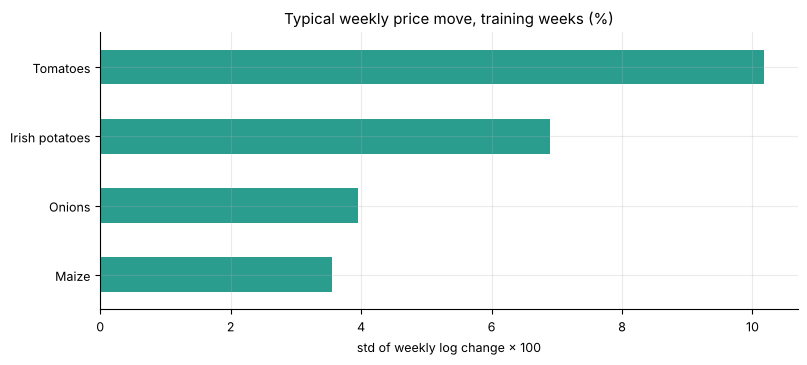

In [2]:
vol = train_ret.std().groupby(crop_of).mean().sort_values()
ax = (vol * 100).plot.barh(color="#2a9d8f", title="Typical weekly price move, training weeks (%)"); ax.set_xlabel("std of weekly log change × 100")
print((vol * 100).round(1).to_string())

Tomatoes move about 4-5 times as much as maize each week. Any model's absolute error will be dominated by tomatoes - another reason to report results per crop and as skill vs naive.

## 2. Persistence: the memory of prices
The **autocorrelation function (ACF)** at lag *k* measures how similar a series is to itself *k* weeks earlier. Compare the ACF of price **levels** with that of weekly **changes**.

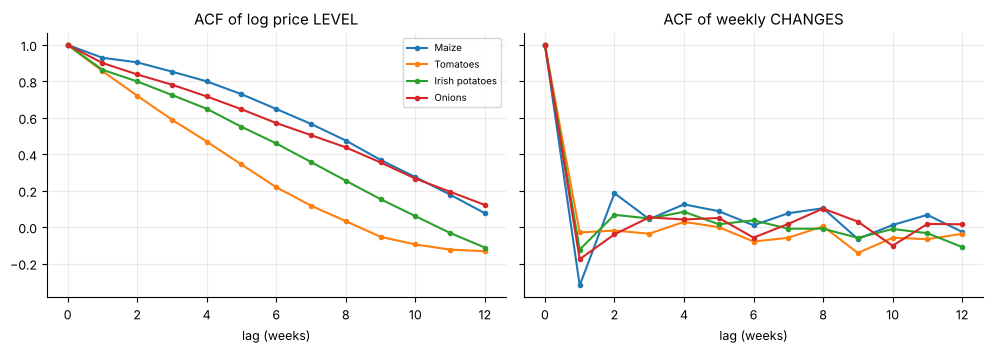

In [3]:
def acf(x, nlags=12):
    x = np.asarray(x, float); x = x[~np.isnan(x)]; x = x - x.mean()
    return np.array([(x[k:] * x[:len(x) - k]).sum() / (x ** 2).sum() for k in range(nlags + 1)])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for crop in CROPS.values():
    cols = crop_of[crop_of == crop].index
    axes[0].plot(np.mean([acf(train_lp[c]) for c in cols], 0), marker="o", ms=3, label=crop)
    axes[1].plot(np.mean([acf(train_ret[c].dropna()) for c in cols], 0), marker="o", ms=3, label=crop)
axes[0].set_title("ACF of log price LEVEL"); axes[1].set_title("ACF of weekly CHANGES")
for a in axes: a.set_xlabel("lag (weeks)")
axes[0].legend(fontsize=7); plt.tight_layout()

Levels are strongly autocorrelated (this week's price is a very good guide to next week's: the reason the naive forecast is hard to beat); weekly changes are only weakly so.
The practical consequence: **model the change relative to the latest price, not the level** - that is what the pipeline's ML models predict.

A formal check is the **Augmented Dickey-Fuller test**, which asks whether a series keeps wandering (unit root) or returns to a mean (stationary).

In [4]:
try:
    from statsmodels.tsa.stattools import adfuller
    rows = []
    for c in train_lp.columns:
        x = train_lp[c].dropna().values
        rows.append(dict(crop=crop_of[c], level_p=adfuller(x, autolag="AIC")[1], change_p=adfuller(np.diff(x), autolag="AIC")[1]))
    adf = pd.DataFrame(rows).groupby("crop").agg(share_levels_stationary=("level_p", lambda p: (p < .05).mean()),
                                                 share_changes_stationary=("change_p", lambda p: (p < .05).mean()))
    print(adf.round(2))
except ImportError:
    print("statsmodels not installed - skipping the ADF test (pip install statsmodels)")

                share_levels_stationary  share_changes_stationary
crop                                                             
Irish potatoes                      0.4                       1.0
Maize                               1.0                       0.2
Onions                              0.0                       1.0
Tomatoes                            0.4                       1.0


Read this table with suspicion: it does not tell one consistent story. Maize levels look stationary (100%) but maize *changes* only 20% of the time; onion levels never do (0%), yet every onion series
has stationary changes. With ~100 observations per series the test has little power, and differencing an already mean-reverting series (over-differencing) confuses it further.
The lesson is not "which crop is stationary" but **"do not base a modelling decision on a unit-root test of 100 points"**. The pipeline sidesteps the question: it models the *change relative to the latest price*,
which is what notebook 08 does.

## 3. Seasonality: how many cycles do we actually have?
The average price deviation by calendar month, **from training weeks only** - that is just *two* annual cycles.

Irish potatoes    4
Maize             6
Onions            1
Tomatoes          2


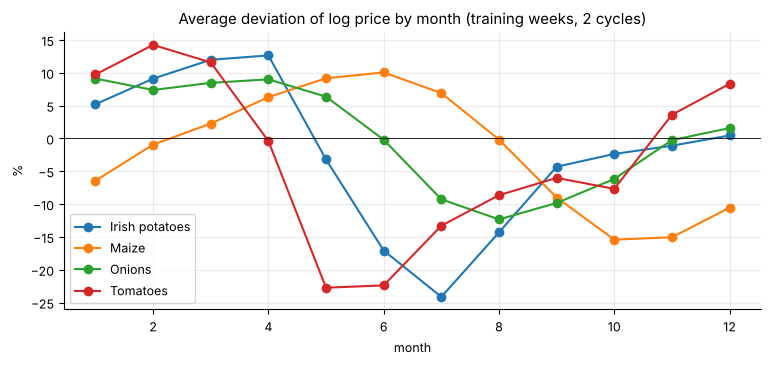

In [5]:
dates = START_DATE + pd.to_timedelta((lp.index.values - 1) * 7, unit="D")
month = pd.Series(dates.month, index=lp.index)
dev = lp - lp.mean()
def monthly_profile(upto):
    d = dev.loc[:upto]
    return d.groupby(month.loc[:upto]).mean().T.groupby(crop_of).mean().T       # month x crop

prof_train = monthly_profile(TRAIN_END)
ax = (prof_train * 100).plot(marker="o", title="Average deviation of log price by month (training weeks, 2 cycles)"); ax.set_ylabel("%"); ax.set_xlabel("month"); ax.axhline(0, color="k", lw=.6)
peak = prof_train.idxmax().rename("month of highest price"); print(peak.to_string())

Different crops peak in different months and with different amplitude - one shared calendar pattern would not fit everybody. With two cycles, though, the estimates are noisy: a single unusual season shifts them.

## 4. Do markets move together?
Correlation of weekly changes between the five markets, averaged within each crop (training weeks).

In [6]:
rows = {}
for crop in CROPS.values():
    cols = crop_of[crop_of == crop].index
    cm = train_ret[cols].corr().values
    rows[crop] = cm[np.triu_indices(len(cols), 1)].mean()
print(pd.Series(rows, name="mean pairwise correlation of weekly changes").round(2).to_string())

Maize             0.19
Tomatoes          0.14
Irish potatoes    0.09
Onions            0.04


**Reading the result:** the same-week co-movement is *low* (about 0.04-0.19). Most weekly movement is market-specific noise. So if neighbouring markets help forecasting at all, it is not through
"they moved together this week" but through **levels and lags** - how far a market's price sits from its neighbours' prices, and what the neighbours did *last* week (the generator builds in a one-week-lag transmission). Notebook 08 tests that.

## 5. Do the drivers relate to *next* week's price change?
For each driver we form an *anomaly* (today vs its recent average), and correlate it with the **next** week's log price change - using only information at the origin. The relationship should
have the economically sensible sign: more supply → price falls.

In [7]:
def anomaly(col):
    x = wide(rl, col).ffill(limit=4)
    return np.log(x) - np.log(x.rolling(13, min_periods=6).mean().shift(1))
drivers = {"arrivals anomaly": anomaly("market_arrivals_tonnes"), "demand anomaly": anomaly("estimated_demand_index"),
           "drought index (lag 4)": wide(rl, "drought_index").shift(4), "fuel change over 4 wks": np.log(wide(rl, "fuel_cost_index")) - np.log(wide(rl, "fuel_cost_index")).shift(4)}
nxt = ret.shift(-1)
out = {name: {crop: np.nanmean([d.loc[14:TRAIN_END - 1, c].corr(nxt.loc[14:TRAIN_END - 1, c]) for c in crop_of[crop_of == crop].index])
              for crop in CROPS.values()} for name, d in drivers.items()}
pd.DataFrame(out).round(3)

,arrivals anomaly,demand anomaly,drought index (lag 4),fuel change over 4 wks
Maize,-0.281,-0.056,-0.045,-0.113
Tomatoes,-0.128,0.034,0.005,-0.020
Irish potatoes,-0.301,0.189,0.154,0.047
Onions,-0.212,0.165,0.045,0.068


* The **arrivals anomaly** has the expected negative sign for all four crops (about -0.13 to -0.30; more supply today, a lower price next week) - and, perhaps surprisingly, is *weakest for tomatoes*, the noisiest crop.
* The **demand anomaly** has the expected positive sign for potatoes and onions (about +0.17 to +0.19) but is near zero or even wrong-signed for maize and tomatoes.
* **Drought (lag 4)** and **fuel changes** are weak and inconsistent in sign. A single-lag linear correlation is a poor detector for effects that are *delayed*, *nonlinear* or that only matter in rare episodes -
  a reminder that a weak correlation here does not prove a feature is useless (and a strong one would not prove it is causal).

All correlations are modest: weekly price changes are mostly noise, which is exactly why forecasting skill will turn out to be modest.

## 6. Exploration can leak, too
Imagine you want to analyse "high-volatility weeks". You need a threshold: say, the 75th percentile of recent volatility for each crop. Compare computing it from the **training weeks only**
(what you could know when building the model) with using **all 156 weeks** (what happens if you explore the whole file before splitting).

In [8]:
vol8 = ret.rolling(8, min_periods=5).std()
def threshold(upto):
    return pd.Series({crop: vol8.loc[14:upto, crop_of[crop_of == crop].index].stack().quantile(.75) for crop in CROPS.values()})
thr_train, thr_all = threshold(TRAIN_END), threshold(TEST_END)
test_origins = vol8.loc[VAL_END + 1:TEST_END - 1]
share = lambda thr: pd.Series({crop: (test_origins[crop_of[crop_of == crop].index] > thr[crop]).stack().mean() for crop in CROPS.values()})
cmp = pd.DataFrame({"threshold (train only)": thr_train, "threshold (all weeks)": thr_all,
                    "test weeks flagged high-vol (train thr)": share(thr_train), "test weeks flagged high-vol (all-weeks thr)": share(thr_all)})
cmp.round(3)

,threshold (train only),threshold (all weeks),test weeks flagged high-vol (train thr),test weeks flagged high-vol (all-weeks thr)
Maize,0.040,0.040,0.256,0.256
Tomatoes,0.120,0.124,0.472,0.408
Irish potatoes,0.055,0.057,0.320,0.304
Onions,0.047,0.048,0.336,0.312


Two things to see. First, the test period is *more volatile than training* (47% of tomato test weeks exceed the training-based "high" threshold, versus the 25% you would expect if nothing had changed).
Second, the all-weeks threshold is slightly higher, so fewer test weeks are called high-volatility (tomatoes: about 41% instead of 47%): the **test period itself shaped the definition** used to analyse it.
The effect is modest here, but its direction is systematic: whenever the future differs from the past, a threshold learned from everything hides that difference. No model was trained, yet the analysis already borrowed from the future. The pipeline therefore computes volatility regimes from origins ≤ the end of the *fitting* window only.

## What EDA should (and should not) decide
* ✅ Decide: transformations (log, changes), which feature families to try, horizons that make sense, how to handle missing data and errors, which crops need separate reporting.
* ❌ Do not decide from the validation/test weeks: thresholds, feature selection, seasonal patterns, which model "looks good".
* Keep a written list of every choice that was informed by data, and by which weeks.

## Exercises
1. Recompute section 6 for the 90th percentile instead of the 75th. Does the leakage get bigger or smaller?
2. Repeat the seasonal profile of section 3 using all 156 weeks. How much does the monthly pattern of onions change? What does that tell you about trusting a two-year seasonal estimate?
3. Compute the section-5 correlations at *two*-week and *four*-week lags of the driver instead of one. Which drivers keep their signal?
4. Add `rainfall_mm` (4-week mean) as a driver. Is the correlation with next week's price change visible at all? (Weather works through arrivals with a delay - notebook 02, Step 5.)

**Where this lives in the pipeline:** the full EDA is `scripts/02_audit_and_eda.py` (outputs in `reports/EDA_REPORT.md`); regime thresholds use `vol_threshold` in `src/agriprice/analysis.py`.